# Exercises for Part 2 - using your package

## 1. Something familiar

> **TASK 1:** import your package and use it to solve exercise 1 from Part 1 in the previous assignment (Canon ball range). Compute the range distributions for the two parameter sets and plot their histograms.

In [2]:
# import packages ...

# FOR  TAs
import numpy as np 
from my_package import propagate

In [3]:
# your solution ...

In [4]:
# FOR TAs

# Exercise 1

# seed the random number generator for reproducibility
rng = np.random.default_rng(42) 
n_samples = 10_000
rad_per_deg = np.pi / 180    

# define how the range depends on angle, speed, and gravity
def get_range(theta: float, v: float, g: float) -> float:
    return v**2 / g * np.sin(2 * theta) 

# define input kinds and parameters in the same order as expected in get_range()
inputs = [
    ("normal", 35 * rad_per_deg, 1 * rad_per_deg), # theta
    ("normal", 10, 0.1), # v
    ("constant", 9.82) # g
]

# propagate the inputs to get the range distribution
ranges = propagate(rng, get_range, inputs, n_samples=n_samples)

# compute mean and standard deviation of the range
mean_range = np.mean(ranges)
std_range = np.std(ranges)

# print output
print(f"The estimated range is {mean_range:.2f} +- {std_range:.2f} m")

# plot histograms and repeat for the other parameter choice (theta = 45.0 +- 10.0, v = 10.0 +- 0.0)

The estimated range is 9.57 +- 0.23 m


## 2. Can we trust our detector?

A particle detector in our lab records discrete counts during a fixed observation interval. Even when no signal is present, background radiation produces counts.

Suppose background counts are Poisson distributed with mean 2, while a real event contributes an additional independent Poisson signal with mean 6.

The detector announces a discovery whenever the total observed count reaches a threshold $k$.

**Question:** *what threshold $k$ should we choose to avoid false alarms without missing too many real events?*

The statistical model is:

$$
N_{background} \sim \text{Poisson}(\lambda=2) \\

N_{events} \sim \text{Poisson}(\lambda=6)
$$

Where the detector reports $N = N_{background} + N_{events}$, and the detection function is:

$$
D(N) = \begin{cases}
1 & \text{if } N \geq k \\
0 & \text{if } N < k
\end{cases}
$$

That is: If the detector sees more than $k$ particles, it counts it as an *event.*

> **TASK 2**: Estimate the probability of detection for thresholds $k=3,4,5,6,7$

In [5]:
# your solution ...

# FOR TAs
rng = np.random.default_rng(42)

def detection(n_background: int, n_events: int, k: float) -> int:
    return int(n_background + n_events >= k)

inputs = [
    ("poisson", 2),
    ("poisson", 6),
    ("constant", 3)
]

detections = propagate(rng, detection, inputs, n_samples=1_000)

print(f"The probability of detection for k = 3 is {np.mean(detections):.2f}")

for k in (4, 5, 6, 7):
    inputs[-1] = ("constant", k)
    detections = propagate(rng, detection, inputs, n_samples=1_000)
    print(f"The probability of detection for k = {k} is {np.mean(detections):.2f}")

The probability of detection for k = 3 is 0.98
The probability of detection for k = 4 is 0.95
The probability of detection for k = 5 is 0.90
The probability of detection for k = 6 is 0.80
The probability of detection for k = 7 is 0.70


> **TASK 3:** Repeat with no signal / real events present (replacing events as a `constant` type zero input) to estimate the "false-alarm probability"

In [6]:
# your solution ...

# FOR TAs
rng = np.random.default_rng(42)

inputs = [
    ("poisson", 2),
    ("constant", 0),
    ("constant", 3)
]

for k in (3, 4, 5, 6, 7):
    inputs[-1] = ("constant", k)
    detections = propagate(rng, detection, inputs, n_samples=1_000)
    print(f"The false-alarm probability for k = {k} is {np.mean(detections):.2f}")


The false-alarm probability for k = 3 is 0.32
The false-alarm probability for k = 4 is 0.13
The false-alarm probability for k = 5 is 0.06
The false-alarm probability for k = 6 is 0.02
The false-alarm probability for k = 7 is 0.01


> **TASK 4:** Recommend a threshold that keeps the false-alarm probability below 5% while detecting as many reel events as possible

your answer ...

FOR TAs

Choosing $k=6$ gives an estimated false-alaram probability of 2% while triggering detection 80% of the time, i.e. 20% of measurements are rejected. 

Choosing $k=5$ lowers that fraction to 10% at the cost of a 6% change of a false alarm.

> **TASK 5:** Explain why the mean of the simulated $D$ outputs is more useful than reporting a conventional propagated error bar

FOR TAs

The mean of the outputs is a probability of detection derived from the statistical Poissonian model. The distribution of outputs is a bi-modal pile of binary 0/1 observations. Talking about a +- errorbar in the Gaussian sense is not sensical. 

The probability has a theoretical value determined by the $\lambda$ and $k$ parameters and is as such not "uncertain". We could however estimate the variability in our finite sample estimation by repeating over multiple seeds.


**Expected results for two thresholds**

| value | false-alarm | detection probability |
| --- | --- | --- |
|$k=5$ |	5.27% |	90.04% |
|$k=6$ |	1.66% |	80.88% |

**What they learn:** Monte Carlo can simulate decision-making and competing risks, not just propagate numerical uncertainty. The output of interest is a probability, and a statistically informed decision requires considering competing objectives.

## 3. Which experimental method is better?

Suppose your lab has developed two methods for making a certain measurement: **Method A** and **Method B**, each with a different behavior and time in which they finish. The `method_durations.txt` file in the `data/` folder contains the observed finishing times in seconds for each of the methods after repeating 100 times. The first column is Method A and the second is Method B.

> **TASK 6:**
> 1. Load in the observations - for instance using `numpy.loadtxt()` with `skiprows=1` to ignore the first line.
> 2. Plot the distributions of the two methods as histograms
> 3. Compute the mean and standard deviation of each method. Which do you expect to perform the best? 


Method A: mean = 12.00, std = 9.64
Method B: mean = 12.00, std = 0.92


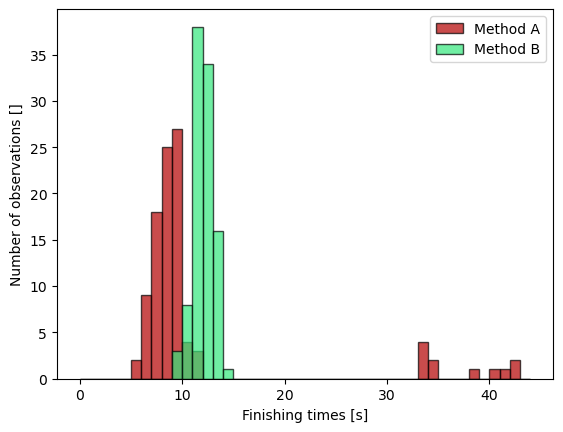

In [7]:
# your solution ...

# FOR TAs
import numpy as np 
import matplotlib.pyplot as plt

data = np.loadtxt("./data/method_durations.txt", delimiter=",", skiprows=1)
method_A = data[:, 0]
method_B = data[:, 1]

bins = np.arange(0, 45, 1).tolist()
plt.hist(method_A, bins=bins, alpha=0.7, label="Method A", edgecolor='black', color="#B30000")
plt.hist(method_B, bins=bins, alpha=0.7, label="Method B", edgecolor='black', color="#34E87C")
plt.xlabel("Finishing times [s]")
plt.ylabel("Number of observations []")
plt.legend()


print(f"Method A: mean = {np.mean(method_A):.2f}, std = {np.std(method_A):.2f}")
print(f"Method B: mean = {np.mean(method_B):.2f}, std = {np.std(method_B):.2f}")
# The two methods perform the same on average and would thus consume the same amount of time over many experiments.
# However, method B has a much lower std deviation which could be preferable if consistency is important.


In order to make a quantitative assessment, your supervisor wants you to find the probability that either method finishes faster for any given single measurement.

> **TASK 7:** Estimate the probability that Method A finishes before Method B and discuss its implications.

In [8]:
# your solution ...

# FOR TAs
rng = np.random.default_rng(42)

def comparison(value1: float, value2: float) -> int:
    return int(value1 < value2) 

inputs = [
    ("empirical", method_A),
    ("empirical", method_B)
]

results = propagate(rng, comparison, inputs, n_samples=100_000)
print(f"Method A is faster than method B in {100 * np.mean(results):.2f}% of the experiments")
print("Despite their averages being identical, method A is very likely to outperform method B in any single experiment.")

Method A is faster than method B in 86.61% of the experiments
Despite their averages being identical, method A is very likely to outperform method B in any single experiment.


Your supervisor points out that the experiment is time sensitive to duration! -  some of the equipment can break if a measurement takes more than 20 seconds. 

> **TASK 8:** Estimate the probability that each method takes more than 20 seconds to complete. Recommend what method you would use in a setting where occasional long delays are especially harmful. Also explain the assumptions we make when we sample independently from the two empirical datasets. 

In [9]:
# your solution ...

# FOR TAs
inputs = [
    ("constant", 20.0),
    ("empirical", method_A),
]

resultsA = propagate(rng, comparison, inputs, n_samples=100_000)
print(f"Method A takes longer than 20 seconds in {100 * np.mean(resultsA):.2f}% of the experiments")


inputs = [
    ("constant", 20.0),
    ("empirical", method_B),
]

resultsB = propagate(rng, comparison, inputs, n_samples=100_000)
print(f"Method B takes longer than 20 seconds in {100 * np.mean(resultsB):.2f}% of the experiments")

# It is clear that method B completely eliminates the risk of catastrophy, while method A has a 12.5% change of triggering it.
# If the risk is genuinely unacceptable, method B is the only viable option.
# By sampling the distributions independently, we assume that there is no correlations between when the two methods
# took what time. I.e. we could imagine that method B is also systematically slower if A was slower etc, which could influence the
# estimated probabilities. 

Method A takes longer than 20 seconds in 12.06% of the experiments
Method B takes longer than 20 seconds in 0.00% of the experiments


This exercise shows that a statistical model lets you address several different questions about the same observations: The mean, the probability of outperforming an alternative, and the probability of catastrophic delay are all distinct quantities that reach beyond the usual $\mu \pm \sigma$ errorbar summary. With your package in hand, you can easily accomodate such questions using monte carlo simulation.

## 4. How many particles hit our detector?

Imagine in a different experiment that we have a detector made from a circular inlet in a `2cm x 2cm` square plate. We fire particles all over the plate, and any particle landing within the circular inlet of radius `1 cm` gets detected - particles landing outside the circle are not detected.

> **TASK 9:** Use your package to estimate what fraction of particles gets detected under the statistical model that particles land uniformly across the entire plate ($X,Y \sim \text{Uniform}(-1, 1)$). Explain what changes you need to make to your package to succeed: what files changed? What did you add/modify?"

In [10]:
# your solution ...

# FOR TAs
rng = np.random.default_rng(42)

def inside(x: float, y: float, r: float) -> int:
    return int(x**2 + y**2 <= r**2)

inputs = [
    ("uniform", -1.0, 1.0), # x
    ("uniform", -1.0, 1.0), # y
    ("constant", 1.0)       # r
]

results = propagate(rng, inside, inputs, n_samples=1_000)
print(f"The estimated probability of a dart landing inside the circle is {np.mean(results):.2f}")

# I had to add a uniform distribution function to .sources.py and a new `elif`` statement 
# in .propagation.py to handle callig the uniform distribution.

The estimated probability of a dart landing inside the circle is 0.78


> **TASK 10:** Estimate the probability of detection $P$ for sample sizes $N = 100, \;1.000, \;100.000, \;1.000.000$ and plot $P$ as a function of $N$ on log-log scale. Use 5 different random seeds for each value of $N$ and compute a standard deviation as an errorbar. What value should $P$ theoretically approach? Fit a power law to the absolute error between $P(N)$ and the theoretical value and interpret the best fit exponent.

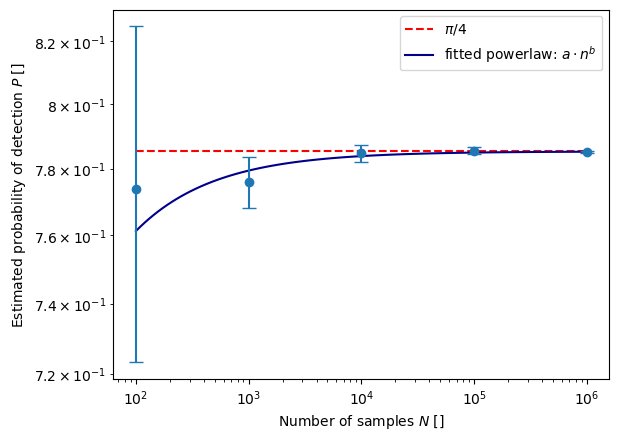

Fitted parameters: a = -0.407, b = -0.614
The best fit exponent is close to 1/sqrt(N), which is expected as the convergence of the standard error of the mean for independent samples.


In [ ]:
# your solution ...

# FOR TAs
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def estimate_probability(base_seed: int, n_samples: int) -> tuple[float, float]:
    """ 
    Estimate the probability of detection for 5 different random seeds and a specified number of samples to draw.
    Args:
        base_seed (int): The base seed for the random number generator. The 5 seeds are derived by adding 0, 1, 2, ... 
        n_samples (int): The number of samples to draw for each seed.
    Returns:
        tuple[float, float]: The mean and standard deviation of the estimated probabilities across the 5 seeds.    
    """
    probabilities = []
    seeds = [base_seed + i for i in range(5)]
    inputs = [
        ("uniform", -1.0, 1.0), # x
        ("uniform", -1.0, 1.0), # y
        ("constant", 1.0)       # r
    ]

    # propagate for each of the seeds
    for seed in seeds:
        rng = np.random.default_rng(seed)
        results = propagate(rng, inside, inputs, n_samples=n_samples)
        probabilities.append(np.mean(results)) # compute the probability as the mean of the results
    # compute the mu +- sigma summary statistics and return as floats
    mu, std = np.mean(probabilities), np.std(probabilities)
    return float(mu), float(std)

# define what n_samples to use and the base seeds. 
n_samples_list = np.array([100, 1_000, 10_000, 100_000, 1_000_000])
base_seeds = [13, 42, 69, 101, 117] # We use different ones to avoid getting the same random numbers across realizations - all should be independent.
means, stds = [], []

# estimate the probabilities for each n_samples and base_seed combination
for n_samples, base_seed in zip(n_samples_list, base_seeds):
    mu, std = estimate_probability(base_seed, n_samples)
    means.append(mu)
    stds.append(std)
means, std = np.array(means), np.array(stds) # convert to numpy arrays for convenience

# fitting: a powerlaw to fit the absolute error between P(N) and the theoretical pi/4
def fit(n: np.ndarray, a: float, b: float) -> np.ndarray:
    return a * n**b

# fit parameters and make a smooth curve for plotting
par, cov = curve_fit(fit, n_samples_list, means - np.pi/4, sigma=stds, absolute_sigma=True)
nn = np.logspace(2, 6, 100)
pp = np.pi/4 + fit(nn, *par)


# theoretical value as the ratio of circle to square area, which is pi/4
plt.hlines(np.pi/4, n_samples_list[0], n_samples_list[-1], color='r', linestyles='dashed', label=r'$\pi/4$')

# plotting
plt.plot(nn, pp, label=r"fitted powerlaw: $a\cdot n^b$", color="darkblue")
plt.errorbar(n_samples_list, means, yerr=stds, fmt='o', capsize=5)
plt.xlabel(r"Number of samples $N$ []")
plt.ylabel(r"Estimated probability of detection $P$ []")
plt.xscale('log')
plt.yscale("log")
plt.legend()
plt.show()

print(f"Fitted parameters: a = {par[0]:.3f}, b = {par[1]:.3f}")
print("The best fit exponent is close to 1/sqrt(N), which is expected as the convergence of the standard error of the mean for independent samples.")

## Conclusions

By now you should have encountered the inconvenience associated with adding a new input type such as `"uniform"` to your package. The problem is that your propagation function is explicitly responsible for recognizing input types and drawing random values. If you or anyone else wants to add new types (say and exponential distribution or maybe something weird you've never even heard of), this structure requires us to go and change the package source code. This makes it rigid and difficult to extend and use in new ways. 

Conceptually, however, there is really no reason that the code should have to change! It is still doing the same thing:
- get random values
- compute the function of interest over all samples
- return the output distribution

It is possible to remove this inconvenience by making a **design change.** The trick is to let the inputs themselves know how to provide the propagation function with random numbers - regardless of what type they are. We can implement this elegantly using a new programming concept known as `Classes`, which will be introduced in lectures surrounding Assignment 3. Using classes, we can allow users to make whatever inputs they can wish for - but importantly **without ever having to change or look at the source code in your package!** Just as you never have to look at the source code behind NumPy.

As an added bonus, Part 3 will teach you to publish your package on GitHub, download a friend's package, and use their work to solve new monte carlo problems.